# 09 - Final comparative analysis: the structural validity framework

**Purpose.** Bring the seven tests together without letting a single metric define "validity".

## Operational definition (see `research/methodology.md`)
A portfolio model is *structurally valid on a sample* to the extent that all of the following hold:
1. **Input robustness (S2):** small, statistically plausible changes in inputs change weights little.
2. **Temporal stability (S1):** weights do not churn from window to window beyond what the market's own evolution warrants.
3. **Honest self-assessment (S3):** ex-ante promised performance is close to realised out-of-sample performance.
4. **Regime consistency (S4):** behaviour does not collapse in a subset of regimes.
5. **Perturbation resilience (S5):** controlled perturbations do not produce disproportionate weight/risk changes.

The composite is a **weight-free rank average** of these components (lower = more valid). It is a *summary device*, not a theorem: always read the components.

In [1]:
import sys, warnings
import os
from pathlib import Path
try:  
    os.chdir(Path(__vsc_ipynb_file__).resolve().parent)
except NameError:
    pass
sys.path.insert(0, os.path.abspath(".."))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import data_processing as dp, covariance_estimators as ce, portfolio_models as pm
from src import stability_tests as st, regime_detection as rd, stress_testing as sx, evaluation as ev
from src.backtesting import walk_forward, make_models, in_sample_vs_out_of_sample
plt.rcParams["figure.dpi"] = 110
TABLE_DIR = Path("../results/tables")
FIGURE_DIR = Path("../results/figures")
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
_candidates = ["returns_simple_daily.csv"]
_path = next((Path("../data/processed") / f for f in _candidates if (Path("../data/processed") / f).exists()), None)
if _path is None:
    raise FileNotFoundError("Run notebook 01 first: expected ../data/processed/returns_simple_daily.csv")
returns = pd.read_csv(_path, index_col=0, parse_dates=True)
print("loaded:", _path.name)
X = returns.to_numpy()
WINDOW = 504
print(returns.shape, returns.index[0].date(), "->", returns.index[-1].date())

loaded: returns_simple_daily.csv
(3519, 5) 2012-01-04 -> 2025-12-31


## 1. Re-compute the ingredients
(Takes a few minutes; this is the same computation as `scripts/run_pipeline.py`.)

In [2]:
models = make_models({m: pm.MODELS[m].fn for m in pm.CORE_TEN})
res = walk_forward(returns, models, window=WINDOW, rebalance_every=21, cost_bps=10)
perf = ev.performance_table(res.net_returns, res.mean_turnover(), res.mean_effective_n())
gap = in_sample_vs_out_of_sample(res, ev.sharpe_ratio)
wsum = st.weight_stability_summary(res.weights)

last = X[-WINDOW:]
sens = pd.DataFrame({m: st.weight_sensitivity_to_sampling(pm.MODELS[m], last, n_boot=100) for m in pm.CORE_TEN}
                    ).T[["mean_L1_distance", "mean_turnover_equiv"]].astype(float)
mkt = rd.market_proxy(returns, "SPY" if "SPY" in returns else None)
reg_tab = ev.regime_conditional_performance(res.net_returns, rd.volatility_regimes_ex_post(mkt))
pert = sx.compare_models_under_perturbation({m: pm.MODELS[m] for m in pm.CORE_TEN}, last,
                                            lambda x, lev, rng: sx.perturb_mean(x, lev, rng), level=1.0, n_rep=30)
comp = st.structural_validity_table(wsum, sens, gap, reg_tab, pert)
perf.to_csv(TABLE_DIR / "final_comparative_oos_performance.csv", index_label="model")
gap.to_csv(TABLE_DIR / "final_comparative_is_oos_sharpe_gap.csv", index_label="model")
wsum.to_csv(TABLE_DIR / "final_comparative_weight_stability.csv", index_label="model")
sens.to_csv(TABLE_DIR / "final_comparative_sampling_sensitivity.csv", index_label="model")
reg_tab.to_csv(TABLE_DIR / "final_comparative_regime_performance.csv", index=False)
pert.to_csv(TABLE_DIR / "final_comparative_mean_perturbation.csv", index_label="model")
comp.to_csv(TABLE_DIR / "final_structural_validity_comparison.csv", index_label="model")
comp.round(3)

,S1_weight_instability,S2_input_sensitivity,S3_overfitting_gap,S4_regime_inconsistency,S5_perturbation_fragility,composite_rank_score
equal_weight,0.000,0.000,-0.033,0.092,0.000,1.4
min_vol_capped,0.010,0.068,-0.063,0.126,0.000,3.6
gmv_long_only,0.008,0.026,0.189,0.413,0.000,4.0
risk_parity,0.008,0.032,-0.020,0.148,0.000,4.0
ledoit_wolf_minvar,0.012,0.025,0.182,0.393,0.000,4.2
cond_vol_minvar,0.087,0.107,0.203,0.464,0.000,5.8
mean_variance,0.075,0.144,0.412,0.374,0.193,6.4
black_litterman,0.184,0.183,0.586,0.065,0.312,7.2
robust_mv,0.118,0.218,0.609,0.472,0.312,8.8
max_sharpe,0.098,0.281,0.732,0.496,0.342,9.6


**The composite favors equal weight and a small group of low-churn, less mean-dependent models—but it is a rank summary, not a direct measure of return or statistical significance.** The score is the average of each model’s ranks across five components, with lower being better; it is not a percentage or “validity” scale (`implementation`).

- **Equal weight ranks first (1.4).** Its zero instability, sensitivity, and perturbation scores are largely by construction: its weights do not respond to estimated inputs. It also has a modestly negative overfitting gap (−0.033) and low regime dispersion (0.092).
- **Capped minimum volatility (3.6), GMV and risk parity (4.0), and Ledoit–Wolf minimum variance (4.2)** form the next-best group. Risk parity and capped minimum volatility combine small gaps with low regime inconsistency; GMV and Ledoit–Wolf score well on weight stability and input sensitivity but have positive overfitting gaps.
- **Conditional-volatility minimum variance (5.8) and mean-variance (6.4)** are intermediate. Mean-variance has a larger overfitting gap (0.412) and nonzero response to mean perturbations.
- **Black–Litterman (7.2), robust MV (8.8), and max-Sharpe (9.6)** rank worst overall. Max-Sharpe has the largest overfitting gap (0.732), input sensitivity (0.281), and regime dispersion (0.496). Black–Litterman is an exception on regime consistency (0.065), but fares poorly on other components.

A key caveat: **S5 here tests only a one-standard-error mean perturbation**, repeated 30 times—not the full range of stresses in notebook 07. The zero scores for equal weight and several covariance-focused models mean their weights did not respond to *mean-only* perturbations; they do not establish resilience to every kind of shock.

Taken together, the table supports a **relative structural-stability advantage** for equal weight, capped minimum volatility, and risk parity in this sample. It does not prove a universal best model: the composite weights all five component *ranks* equally, discards the size of differences when ranking, and provides no uncertainty intervals for the composite itself.

## 2. Does the ranking depend on which component you drop?

In [3]:
drop = st.composite_robustness_to_dropping(comp)
drop_summary = drop.assign(full=comp["composite_rank_score"]).round(2).sort_values("full")
drop_summary.to_csv(TABLE_DIR / "composite_rank_leave_one_component_out.csv", index_label="dropped_component")
drop_summary

,without_S1_weight_instability,without_S2_input_sensitivity,without_S3_overfitting_gap,without_S4_regime_inconsistency,without_S5_perturbation_fragility,full
equal_weight,1.50,1.50,1.25,1.25,1.50,1.4
min_vol_capped,3.50,3.25,4.25,3.75,3.25,3.6
gmv_long_only,4.50,4.25,3.75,3.25,4.25,4.0
risk_parity,4.25,4.00,4.25,4.00,3.50,4.0
ledoit_wolf_minvar,4.00,4.75,4.25,3.75,4.25,4.2
cond_vol_minvar,5.50,5.75,5.75,5.25,6.75,5.8
mean_variance,6.50,6.25,6.25,6.75,6.25,6.4
black_litterman,6.50,7.00,7.00,8.75,6.75,7.2
robust_mv,8.75,8.75,8.75,8.75,9.00,8.8
max_sharpe,10.00,9.50,9.50,9.50,9.50,9.6


**Interpret:** compute Spearman correlations between the full ranking and each drop-one ranking. If one component dominates the ordering, say so - the composite is then not a balanced summary.



| Component omitted | Spearman \(\rho\) |
|---|---:|
| S1 weight instability | 0.957 |
| S2 input sensitivity | 0.997 |
| S3 overfitting gap | 0.954 |
| S4 regime inconsistency | 0.942 |
| S5 perturbation fragility | 0.969 |

All five correlations are high, so **no single component appears to dominate the overall ordering**. The ranking is robust to dropping any one component: equal weight remains best, and max-Sharpe and robust MV remain near the bottom. S2’s omission changes the ordering least; dropping S4 changes it most, notably worsening Black–Litterman’s score because its comparatively low regime inconsistency had helped its full composite.

The middle ranks do shift, so don’t overstate the exact ordering among those models. These correlations are descriptive and based on only ten models; they show rank stability under this check, not statistical certainty or proof that the five dimensions are equally informative.

In [4]:
from scipy.stats import spearmanr
rank_robustness = pd.Series(
    {c: round(spearmanr(comp["composite_rank_score"], drop[c])[0], 3) for c in drop},
    name="spearman_rho",
).to_frame()
rank_robustness.to_csv(TABLE_DIR / "composite_rank_spearman_robustness.csv", index_label="dropped_component")
rank_robustness

{'without_S1_weight_instability': np.float64(0.957),
 'without_S2_input_sensitivity': np.float64(0.997),
 'without_S3_overfitting_gap': np.float64(0.954),
 'without_S4_regime_inconsistency': np.float64(0.942),
 'without_S5_perturbation_fragility': np.float64(0.969)}

## 3. The central question: performance vs structure

Spearman(Sharpe, composite): SignificanceResult(statistic=np.float64(-0.5045616012544536), pvalue=np.float64(0.13694196641606443))


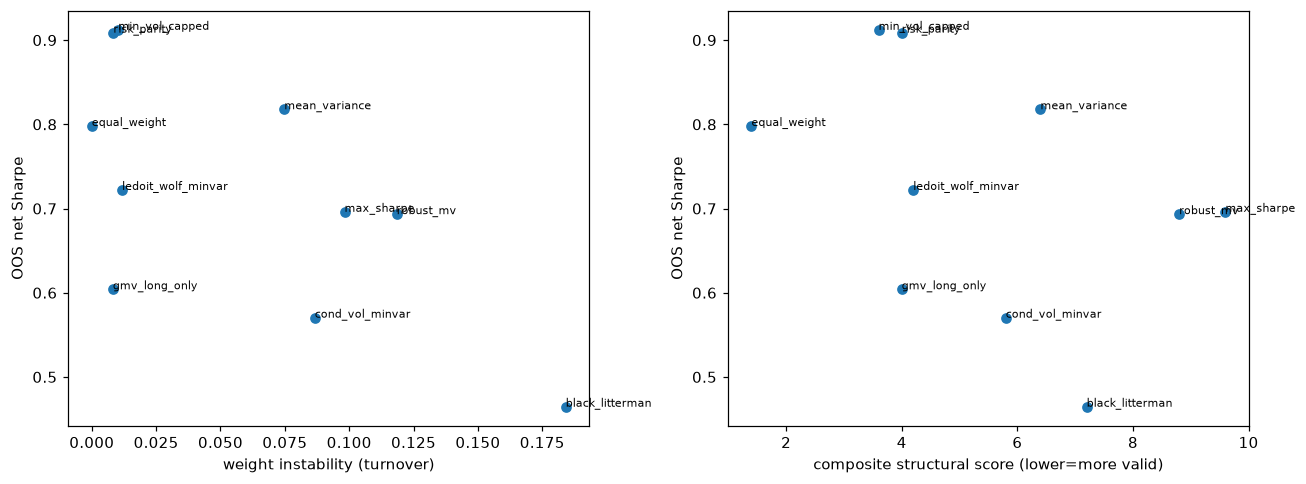

In [5]:
df = comp.join(perf[["sharpe", "calmar", "max_drawdown"]])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(df["S1_weight_instability"], df["sharpe"])
ax[1].scatter(df["composite_rank_score"], df["sharpe"])
for m in df.index:
    ax[0].annotate(m, (df.loc[m, "S1_weight_instability"], df.loc[m, "sharpe"]), fontsize=7)
    ax[1].annotate(m, (df.loc[m, "composite_rank_score"], df.loc[m, "sharpe"]), fontsize=7)
ax[0].set_xlabel("weight instability (turnover)"); ax[1].set_xlabel("composite structural score (lower=more valid)")
for a in ax: a.set_ylabel("OOS net Sharpe")
plt.tight_layout()
df.to_csv(TABLE_DIR / "structural_validity_vs_oos_sharpe_data.csv", index_label="model")
fig.savefig(FIGURE_DIR / "structural_validity_vs_oos_sharpe.png", dpi=150, bbox_inches="tight")
from scipy.stats import spearmanr
print("Spearman(Sharpe, composite):", spearmanr(df["sharpe"], df["composite_rank_score"]))

**Interpret (this is the project's core finding - write it in your own words, with numbers):**
- Is there a relationship between structural instability and out-of-sample Sharpe? Direction and strength?
- With only ten models, how many data points are behind this correlation, and how much should you trust it?
- Identify any model with an attractive Sharpe but poor structural scores (the "attractive but unstable" case) - or show that none exists in your sample. Either result is reportable.

**Composite structural score vs. OOS net Sharpe:** \(\rho=-0.505\), \(n=10\), nominal \(p\approx0.137\). Since higher composite scores mean *less* structural validity, this is a moderate negative association: less-valid models tended to have lower Sharpe.
- **Weight instability (turnover) vs. OOS net Sharpe:** \(\rho=-0.578\), \(n=10\), nominal \(p\approx0.080\). This also points in the expected direction, but is not conclusive.

There are **10 model-level observations**, not thousands of independent daily observations. The models share the same sample and are not independent, so treat these as exploratory correlations—not strong evidence of a general relationship.

There is **no clear “attractive but unstable” outlier** here. Capped minimum volatility and risk parity have the best Sharpes (**0.912** and **0.909**) and relatively favorable structural scores (**3.6** and **4.0**, lower is better). Max-Sharpe has the worst structural score (**9.6**) but only a **0.696** Sharpe; Black–Litterman and robust MV also pair weaker Sharpes with poor structural scores. This sample’s strongest performers are therefore also among its more structurally stable models, though the small cross-model sample limits that conclusion.

## 4. Claims-vs-evidence ledger
Fill this table honestly after you have run everything. A claim with no supporting cell above does not go in the paper.

In [6]:
ledger = pd.DataFrame({
    "Hypothesis": ["H1 optimised beats 1/N OOS net of costs", "H2 shrinkage improves weight stability",
                   "H3 robust optimisation reduces input sensitivity", "H4 weights less stable in stress",
                   "H5 estimation error materially raises realised risk", "H6 gains are economically meaningful",
                   "H7 simple methods win after costs"],
    "Evidence (table / figure)": [""] * 7,
    "Verdict (supported / not supported / inconclusive)": [""] * 7,
    "Caveat": [""] * 7})
ledger.to_csv(TABLE_DIR / "hypothesis_evidence_ledger.csv", index=False)
ledger

,Hypothesis,Evidence (table / figure),Verdict (supported / not supported / inconclusive),Caveat
0,H1 optimised beats 1/N OOS net of costs,,,
1,H2 shrinkage improves weight stability,,,
2,H3 robust optimisation reduces input sensitivity,,,
3,H4 weights less stable in stress,,,
4,H5 estimation error materially raises realised...,,,
5,H6 gains are economically meaningful,,,
6,H7 simple methods win after costs,,,


## 5. What would falsify your conclusions?
List at least three analyses that could overturn your findings (different universe, different period, different covariance estimator, different cost model, a significance test with proper multiple-testing control) and mark which you have done.

### What would falsify these conclusions?
- **Different asset universe — Not done.** Repeat the analysis with a broader, investable universe that accounts for delisted assets. If the structural ranking or Sharpe relationship reverses, the current result is universe-specific. The current analysis uses five ETFs over 2012–2025.
- **Different periods and estimation schemes — Partly done.** compares 252- and 504-day rolling windows, a 756-day window with 63-day rebalancing, and an expanding window. It also examines regimes and historical stress scenarios. These are not independent calendar-period replications, and the 756-day variant changes rebalance frequency as well as window length. A separate period could overturn the current ranking.
- **Alternative covariance estimators — Partly done.** The models use different covariance approaches, and examines covariance stability. However, the full structural comparison has not been rerun as a controlled estimator swap for the same portfolio rules. If that changed the ranking substantially, estimator choice would be a key limitation.
- **Different transaction-cost assumptions — Done, within limits.** tests 0, 5, 10, 25, and 50 bps. A different cost model—such as spreads and market impact rather than a turnover-based bps charge—could still change the results.
- **Multiple-testing control — Partly done.** A Bonferroni threshold of \(0.05/9 \approx 0.0056\) was applied to the nine model-versus-equal-weight tests in the interpretation; none passed. The notebook’s reported p-values remain unadjusted, and this correction does not validate the separate cross-model correlation.